# Fakhriatu J Koni (23031554186)
# UTS GRAF SAINS DATA 23B


In [ ]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "utsgrafkoni")

def add_friend(driver, name, friend_name):
    with driver.session() as session:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name, friend_name=friend_name
        )

def print_friends(driver, name):
    with driver.session() as session:
        result = session.run(
            "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
            "RETURN friend.name ORDER BY friend.name",
            name=name
        )
        for record in result:
            print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


Pertanyaan Pendahuluan (Checkpoint)

> 1. Nama Database yang digunakan adalah neo4j
> 2. USE di dalam kueri Cyhper 
> 3. Graf sosial atau friendship network merepresentasikan entitas manusia (person) yang terhubung oleh relasi pertemanan ([:KNOWS])

### Import Dataset RetailRocket ke Neo4j

In [ ]:
import os
import sys
from argparse import ArgumentParser
from neo4j import GraphDatabase

def parse_arguments():
    parser = ArgumentParser(description="Impor dataset RetailRocket (events.csv) ke database Neo4j.")
    parser.add_argument("-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default="utsgrafkoni", help="Password Neo4j (sesuaikan passwordmu)")
    parser.add_argument("-b", "--bolt", default="neo4j://127.0.0.1:7687", help="Neo4j URI / Bolt")
    parser.add_argument("-s", "--source", default="ecommerce-data", help="Direktori/folder sumber data (sesuaikan dengan nama folder hasil ekstrakmu)")
    return parser.parse_args(args=[]) 

args = parse_arguments()

csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)
else:
    print(f"File ditemukan di: {csv_file_path}")

try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Berhasil terhubung ke database Neo4j!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

File ditemukan di: ecommerce-data\events.csv
Berhasil terhubung ke database Neo4j!


C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\2216844597.py:30: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [ ]:
import os
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "utsgrafkoni")  

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi berhasil!")

batch_size = 5000
csv_file_path = os.path.join("ecommerce-data", "events.csv")

Koneksi berhasil!


C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\2002118008.py:11: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [ ]:
def clear_data_only(tx):
    tx.run("MATCH (n) DETACH DELETE n")

In [ ]:
def drop_constraint_only(tx):
    tx.run("DROP CONSTRAINT event_id IF EXISTS")

In [ ]:
def import_batch(tx, records):
    query = """
    UNWIND $records AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    CREATE (e:Event {
        timestamp: row.timestamp,
        event: row.event,
        transactionid: row.transactionid
    })
    MERGE (v)-[:PERFORMED]->(e)
    MERGE (e)-[:ON_ITEM]->(i)
    """
    tx.run(query, records=records)

In [ ]:
"""Impor RetailRocket ke Neo4j - mengikuti struktur soal UTS (no.3-5), versi cepat.
 
Jalankan:
  python import_soal.py -p PASSWORD
Opsional filter periode (epoch milidetik diubah ke tanggal):
  python import_soal.py -p PASSWORD --start 2015-06-01 --end 2015-07-01
"""
import argparse
import os
import sys
 
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm
 
 
def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument("-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default="neo4j", help="Password Neo4J (default: neo4j)")
    parser.add_argument("-b", "--bolt", default="neo4j://127.0.0.1:7687",
                        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)")
    parser.add_argument("-s", "--source", default="data",
                        help="Direktori/folder sumber data (default: data)")
    parser.add_argument("-d", "--database", default="neo4j", help="Nama database (default: neo4j)")
    parser.add_argument("--batch-size", type=int, default=20000)
    parser.add_argument("--start", default=None, help="Filter awal, mis. 2015-06-01")
    parser.add_argument("--end", default=None, help="Filter akhir (eksklusif), mis. 2015-07-01")
    parser.add_argument("--filtered-csv", default="events_filtered.csv",
                        help="File CSV hasil filter periode")
    return parser.parse_args()
 
 
def run_write(session, fn, *a):
    f = getattr(session, "execute_write", None) or session.write_transaction
    return f(fn, *a)
 
 
def create_constraints(session):
    """Kunci kecepatan: constraint = index, sehingga MERGE/MATCH tidak scan semua node."""
    pairs = [
        ("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE",
         "CREATE CONSTRAINT ON (v:Visitor) ASSERT v.visitorId IS UNIQUE"),
        ("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE",
         "CREATE CONSTRAINT ON (i:Item) ASSERT i.itemId IS UNIQUE"),
    ]
    for q_new, q_old in pairs:
        try:
            session.run(q_new).consume()
        except Exception:
            try:
                session.run(q_old).consume()
            except Exception as e:
                print(f"Info constraint: {e}")
    session.run("CALL db.awaitIndexes(300)").consume()
 

In [39]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

# 2.1 Wrangling dan EDA

Membaca dataset CSV

In [42]:
import pandas as pd

df = pd.read_csv("ecommerce-data/events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df.shape)
print(df.dtypes)
print(df.head())

print(df["event"].value_counts())
print("Visitor unik:", df["visitorid"].nunique())
print("Item unik   :", df["itemid"].nunique())
print("Rentang     :", df["datetime"].min(), "->", df["datetime"].max())

print(df.isna().sum())
print(df.groupby("event")["transactionid"].count())

(2756101, 6)
timestamp                 int64
visitorid                 int64
event                       str
itemid                    int64
transactionid           float64
datetime         datetime64[ms]
dtype: object
       timestamp  visitorid event  itemid  transactionid  \
0  1433221332117     257597  view  355908            NaN   
1  1433224214164     992329  view  248676            NaN   
2  1433221999827     111016  view  318965            NaN   
3  1433221955914     483717  view  253185            NaN   
4  1433221337106     951259  view  367447            NaN   

                 datetime  
0 2015-06-02 05:02:12.117  
1 2015-06-02 05:50:14.164  
2 2015-06-02 05:13:19.827  
3 2015-06-02 05:12:35.914  
4 2015-06-02 05:02:17.106  
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64
Visitor unik: 1407580
Item unik   : 235061
Rentang     : 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
timestamp              0
visitorid   

Memfilter data berdasarkan periode

In [ ]:
mask_p1 = (df["datetime"] >= "2015-06-06") & (df["datetime"] < "2015-08-07")
mask_p2 = (df["datetime"] >= "2015-08-15") & (df["datetime"] < "2015-08-31")

df_p1 = df[mask_p1].copy()
df_p2 = df[mask_p2].copy()

for nama, d in [("P1", df_p1), ("P2", df_p2)]:
    print(f"{nama}: {len(d):,} baris | "
          f"{d['datetime'].min()} -> {d['datetime'].max()}")

print(df_p1["event"].value_counts())
print(df_p2["event"].value_counts())

print("Visitor P1:", df_p1["visitorid"].nunique())
print("Visitor P2:", df_p2["visitorid"].nunique())
print("Item P1   :", df_p1["itemid"].nunique())
print("Item P2   :", df_p2["itemid"].nunique())

visitor_both = set(df_p1["visitorid"]) & set(df_p2["visitorid"])
print("Visitor di P1 & P2:", len(visitor_both))

item_baru = set(df_p2["itemid"]) - set(df_p1["itemid"])
print("Item P2 yang tidak ada di P1:", len(item_baru))

P1: 1,308,161 baris | 2015-06-06 00:00:00.445000 -> 2015-08-06 23:59:57.486000
P2: 282,649 baris | 2015-08-15 00:00:07.484000 -> 2015-08-30 23:59:52.674000
event
view           1264487
addtocart        32838
transaction      10836
Name: count, dtype: int64
event
view           272523
addtocart        7668
transaction      2458
Name: count, dtype: int64
Visitor P1: 681322
Visitor P2: 160824
Item P1   : 170194
Item P2   : 78501
Visitor di P1 & P2: 10147
Item P2 yang tidak ada di P1: 16833


- Memfilter data P1 sebagai training 
- Memfilter data P2 sebagai testing
- Menentukan kolom yang akan disimpan

In [ ]:
import pandas as pd

df = pd.read_csv("ecommerce-data/events.csv")
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

mask_p1 = (df['datetime'] >= '2015-05-30') & (df['datetime'] <= '2015-07-30')
df_p1 = df[mask_p1].copy()

mask_p2 = (df['datetime'] >= '2015-08-08') & (df['datetime'] <= '2015-08-23')
df_p2 = df[mask_p2].copy()

kolom_asli = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
df_p1[kolom_asli].to_csv("ecommerce-data/events_fakhriatu_p1.csv", index=False)
df_p2[kolom_asli].to_csv("ecommerce-data/events_fakhriatu_p2.csv", index=False)

print(f"Berhasil! File P1: {len(df_p1):,} baris")
print(f"Berhasil! File P2: {len(df_p2):,} baris")

Berhasil! File P1: 1,300,888 baris
Berhasil! File P2: 259,647 baris


In [ ]:
kolom_asli = ["timestamp", "visitorid", "event", "itemid", "transactionid"]

df_p1[kolom_asli].to_csv("ecommerce-data/events_fakhriatu_p1.csv", index=False)
df_p2[kolom_asli].to_csv("ecommerce-data/events_fakhriatu_p2.csv", index=False)

In [52]:
import os

for f in ["ecommerce-data/events_fakhriatu_p1.csv", "ecommerce-data/events_fakhriatu_p2.csv"]:
    cek = pd.read_csv(f)
    print(f, cek.shape, f"{os.path.getsize(f)/1e6:.1f} MB")

ecommerce-data/events_fakhriatu_p1.csv (1300888, 5) 45.8 MB
ecommerce-data/events_fakhriatu_p2.csv (259647, 5) 9.1 MB


Menghubungkan Python ke database Neo4j

In [ ]:
from neo4j import GraphDatabase
from tqdm.auto import tqdm

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "utsgrafkoni") 

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\2034215734.py:8: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


{IPv4Address(('127.0.0.1', 7687)): [{'ttl': 300,
   'servers': [{'addresses': ['127.0.0.1:7687'], 'role': 'WRITE'},
    {'addresses': ['127.0.0.1:7687'], 'role': 'READ'},
    {'addresses': ['127.0.0.1:7687'], 'role': 'ROUTE'}]}]}

C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\2034215734.py:8: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


{IPv4Address(('127.0.0.1', 7687)): [{'ttl': 300,
   'servers': [{'addresses': ['127.0.0.1:7687'], 'role': 'WRITE'},
    {'addresses': ['127.0.0.1:7687'], 'role': 'READ'},
    {'addresses': ['127.0.0.1:7687'], 'role': 'ROUTE'}]}]}

In [60]:
!pip install --upgrade neo4j

  Attempting uninstall: neo4j
    Found existing installation: neo4j 4.2.1
    Uninstalling neo4j-4.2.1:
      Successfully uninstalled neo4j-4.2.1



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [73]:
from neo4j import GraphDatabase
from tqdm.auto import tqdm

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "utsgrafkoni") 

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\2034215734.py:8: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


{IPv4Address(('127.0.0.1', 7687)): [{'ttl': 300,
   'servers': [{'addresses': ['127.0.0.1:7687'], 'role': 'WRITE'},
    {'addresses': ['127.0.0.1:7687'], 'role': 'READ'},
    {'addresses': ['127.0.0.1:7687'], 'role': 'ROUTE'}]}]}

Memastikan database sudah kosong

In [ ]:
from neo4j import GraphDatabase
from tqdm.auto import tqdm
import pandas as pd

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "utsgrafkoni") 

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi berhasil terhubung!")

with driver.session(database="neo4j") as session:
    session.run("MATCH (n) DETACH DELETE n")
    result = session.run("MATCH (n) RETURN count(n) AS jumlah")
    jumlah_node = result.single()["jumlah"]

print("Total simpul setelah dibersihkan:", jumlah_node)  # Harus 0

C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\3752278019.py:10: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi berhasil terhubung!
Total simpul setelah dibersihkan: 0


> Menguji koneksi Python ke Neo4j menggunakan protokol Bolt sekaligus memastikan query Cypher bisa dijalankan

In [ ]:
from neo4j import GraphDatabase

# Ganti 'neo4j://' menjadi 'bolt://'
URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "utsgrafkoni") 

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi berhasil terhubung!")

with driver.session(database="neo4j") as session:
    result = session.run("RETURN 1 AS angka")
    print("Hasil session:", result.single()["angka"])

C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\3605979992.py:8: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi berhasil terhubung!
Hasil session: 1


Membaca dan menampilkan 5 baris pertama

In [80]:
P1_PATH = "ecommerce-data/events_fakhriatu_p1.csv"
P2_PATH = "ecommerce-data/events_fakhriatu_p2.csv"
p1_sample = pd.read_csv(P1_PATH, nrows=5)
p2_sample = pd.read_csv(P2_PATH, nrows=5)
print("Display P1:")
display(p1_sample)
print("\nDisplay P2:")
display(p2_sample)

Display P1:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Display P2:


,timestamp,visitorid,event,itemid,transactionid
0,1439005862995,910095,view,35299,NaN
1,1439006571153,765249,view,60254,NaN
2,1439003025652,16615,view,383084,NaN
3,1439004563586,904951,view,150215,NaN
4,1439006486717,302857,view,324883,NaN


Menghitung jumlah baris data pada file CSV P1 dan P2

In [81]:
def count_csv_rows(path):
    with open(path, "r", encoding="utf-8") as f:
        return sum(1 for _ in f) - 1

p1_rows = count_csv_rows(P1_PATH)
p2_rows = count_csv_rows(P2_PATH)

print("Jumlah baris P1:", p1_rows)
print("Jumlah baris P2:", p2_rows)

Jumlah baris P1: 1300888
Jumlah baris P2: 259647


> Membuat constraint atau aturan pada database Neo4j agar setiap Visitor dan Item memiliki ID yang unik

In [82]:
with driver.session(database="neo4j") as session:
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)
    
    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

print("Constraint berhasil dibuat.")

Constraint berhasil dibuat.


> Memasukkan data event e-commerce dari Python ke Neo4j dan mengubahnya menjadi graf yang terdiri dari Visitor, Item, dan hubungan interaksi

In [83]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {
        visitorId: row.visitorid
    })

    MERGE (i:Item {
        itemId: row.itemid
    })

    FOREACH (_ IN CASE
        WHEN row.event = 'view' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'addtocart' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'transaction' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    )

    RETURN count(*) AS processed
    """

    result = tx.run(
        cypher_query,
        batch=batch
    )

    return result.single()["processed"]


Impor seluruh data CSV ke Neo4j secara bertahap (batch)

In [87]:
def import_csv_to_neo4j(csv_path, batch_size=5000):
    print(f"Mulai import: {csv_path}")
    
    total_rows = count_csv_rows(csv_path)
    chunks = pd.read_csv(
        csv_path,
        chunksize=batch_size
    )

    total_processed = 0

    with driver.session(database="neo4j") as session:

        for chunk in tqdm(
            chunks,
            total=(total_rows + batch_size - 1) // batch_size,
            desc=f"Import {os.path.basename(csv_path)}"
        ):
            # Bersihkan transactionid
            chunk["transactionid"] = (
                chunk["transactionid"]
                .fillna("")
                .astype(str)
            )
            # Pastikan tipe ID konsisten
            chunk["visitorid"] = chunk["visitorid"].astype(int)
            chunk["itemid"] = chunk["itemid"].astype(int)
            chunk["timestamp"] = chunk["timestamp"].astype(int)
            records = chunk.to_dict(
                orient="records"
            )
            processed = session.execute_write(
                import_batch,
                records
            )
            total_processed += processed
    print(
        f"Selesai. Total row diproses: {total_processed}"
    )

Menghitung jumlah baris data dalam file CSV.

In [89]:
def count_csv_rows(path):
    with open(path, "r", encoding="utf-8") as f:
        return sum(1 for _ in f) - 1

> Memasukkan sekumpulan data ke Neo4j dalam satu transaksi

In [90]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {
        visitorId: row.visitorid
    })

    MERGE (i:Item {
        itemId: row.itemid
    })

    FOREACH (_ IN CASE
        WHEN row.event = 'view' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'addtocart' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'transaction' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    )

    RETURN count(*) AS processed
    """
    result = tx.run(cypher_query, batch=batch)
    return result.single()["processed"]

## Chyper query yang digunakan :

### UNWIND $batch AS row
> menguraikan (unwind) kumpulan daftar data (batch) dari kumpulan data menjadi baris-baris agar setiap baris dapat diproses oleh Neo4j.

### MERGE (v:Visitor { visitorId: row.visitorid })

### MERGE (i:Item { itemId: row.itemid })
> mencocokan simpul berdasarkan ID, sudah ada di dalam database? kalau sudah ada Neo4j akan menggunakan kembali kalau belum Neo4j akan membuat simpul baru.
> - (v:Visitor) : simpul pengunjung dengan properti visitorId.
> - (i:Item) : simpul produk dengan properti itemId.
> - row.visitorid dan row.itemid : nilai ID pengunjung dan produk dari setiap baris data.

### FOREACH dan CASE
> menentukan jenis relasi yang dibuat berdasarkan nlai pada kolom row.event. CASE WHEN memeriksa jenis interaksi, sedangkan FOREACH menjalankan perintah CREATE jika kondisi terpenuhi. jenis relasi :
> - view : membuat relasi VIEWED dengan properti timestamp.
> - addtocart : membuat relasi ADDED_TO_CART dengan properti timestamp.
> - transaction : membuat relasi BOUGHT dengan properti timestamp dan transactionId.

### RETURN count(*) AS processed
> menghitung jumlah baris data yang berhasil diproses dan diselesaikan dalam eksekusi batch lalu mengembalikan nilainya ke Python sebagai konfirmasi.

Mengimpor seluruh isi file CSV ke Neo4j secara bertahap menggunakan batch berukuran 5.000 baris

In [94]:
def import_csv_to_neo4j(csv_path, batch_size=5000):
    print(f"Mulai import: {csv_path}")
    
    total_rows = count_csv_rows(csv_path)
    chunks = pd.read_csv(
        csv_path,
        chunksize=batch_size
    )

    total_processed = 0

    with driver.session(database="neo4j") as session:
        for chunk in tqdm(
            chunks,
            total=(total_rows + batch_size - 1) // batch_size,
            desc=f"Import {os.path.basename(csv_path)}"
        ):
            # Bersihkan transactionid
            chunk["transactionid"] = (
                chunk["transactionid"]
                .fillna("")
                .astype(str)
            )
            # Pastikan tipe ID konsisten
            chunk["visitorid"] = chunk["visitorid"].astype(int)
            chunk["itemid"] = chunk["itemid"].astype(int)
            chunk["timestamp"] = chunk["timestamp"].astype(int)
            
            records = chunk.to_dict(
                orient="records"
            )
            processed = session.write_transaction(
                import_batch,
                records
            )
            total_processed += processed
            
    print(
        f"Selesai. Total row diproses: {total_processed:,}"
    )

Impor file P1 ke database

In [95]:
P1_PATH = "ecommerce-data/events_fakhriatu_p1.csv" 
P2_PATH = "ecommerce-data/events_fakhriatu_p2.csv"

# Jalankan import untuk P1 terlebih dahulu
import_csv_to_neo4j(P1_PATH, batch_size=5000)

Mulai import: ecommerce-data/events_fakhriatu_p1.csv


Import events_fakhriatu_p1.csv: 100%|██████████| 261/261 [03:11<00:00,  1.36it/s]

Selesai. Total row diproses: 1,300,888


In [97]:
!pip install networkx matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ------------------------ --------------- 1.3/2.1 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 5.4 MB/s  0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.3 MB 9.1 MB/s eta 0:00:01
   ------------- -------------------------- 3.1/9.3 MB 7.6 MB/s eta 0:00:01
   -------------------- ------------------- 4.7/9.3 MB 7.1 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 8.0 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 8.6 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 8.1 MB/s  0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   --


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


> mengambil sebagian data graf dari Neo4j, mengubahnya menjadi graf NetworkX, lalu memvisualisasikan hubungan antara Visitor dan Item

Jumlah Visitor: 84
Jumlah Item: 5
Jumlah edge: 84


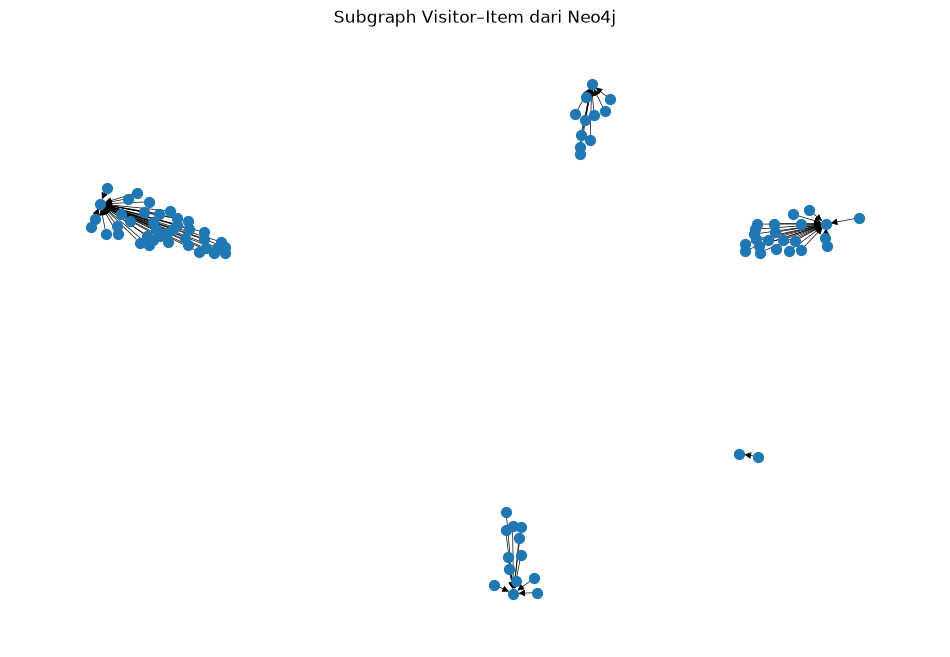

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

query_subgraph = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v.visitorId AS visitorid,
       i.itemId AS itemid,
       type(r) AS interaction
LIMIT 100
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_subgraph)
    records = [record.data() for record in result]


G = nx.DiGraph()

for record in records:
    visitor = f"V_{record['visitorid']}"
    item = f"I_{record['itemid']}"

    G.add_node(visitor, node_type="Visitor")
    G.add_node(item, node_type="Item")
    G.add_edge(
        visitor,
        item,
        interaction=record["interaction"]
    )

print(
    "Jumlah Visitor:",
    sum(1 for n in G.nodes if G.nodes[n]["node_type"] == "Visitor")
)
print(
    "Jumlah Item:",
    sum(1 for n in G.nodes if G.nodes[n]["node_type"] == "Item")
)
print("Jumlah edge:", G.number_of_edges())

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos=pos,
    with_labels=False,
    node_size=50,
    width=0.5,
    arrows=True
)

plt.title("Subgraph Visitor–Item dari Neo4j")
plt.axis("off")
plt.show()

> - Jumlah Visitor : 84 (pengunjung unik yang muncul dalam subgraf hasil query)
> - Jumlah Item : 5 (produk unik yang berinteraksi dengan pengunjung tsb)
> - Jumlah edge : 84 (hubungan terarah Visitor → Item yang tersimpan di graf NetworkX)

> subgraf yang divisualisasikan menunjukkan 84 pengunjung terhubung dengan 5 produk melalui 84 edge. Untuk mengetahui berapa kali setiap produk dilihat, dimasukkan ke keranjang, atau dibeli, kita perlu menganalisis jenis interaksi dan frekuensinya secara terpisah

Menghitung total simpul (node) dan total relasi (relationship) yang ada di database Neo4j

In [105]:

import pandas as pd

query_summary = """
CALL {
    MATCH (n)
    RETURN count(n) AS total_simpul
}
CALL {
    MATCH ()-[r]->()
    RETURN count(r) AS total_relasi
}
RETURN total_simpul, total_relasi
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_summary)
    records = [record.data() for record in result]

df_summary = pd.DataFrame(records)
display(df_summary)


,total_simpul,total_relasi
0,841277,1300888


## VSM terhadap USER

> Mengambil seluruh data interaksi Visitor dengan Item dari Neo4j, lalu mengubahnya menjadi DataFrame pandas sebagai persiapan analisis VSM (Visitor–Item).

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

query_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitorId, i.itemId AS itemId, type(r) AS eventType
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_vsm)
    data = [record.data() for record in result]

df_vsm = pd.DataFrame(data)
print("Total baris interaksi yang ditarik:", len(df_vsm))
print(df_vsm.head())

Total baris interaksi yang ditarik: 1300888
   visitorId  itemId eventType
0     257597  355908    VIEWED
1      62710  355908    VIEWED
2     979686  355908    VIEWED
3     981382  355908    VIEWED
4    1080757  355908    VIEWED


In [128]:
!pip install scipy

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
    --------------------------------------- 0.8/36.6 MB 5.2 MB/s eta 0:00:07
   -- ------------------------------------- 2.4/36.6 MB 6.8 MB/s eta 0:00:06
   --- ------------------------------------ 3.4/36.6 MB 6.1 MB/s eta 0:00:06
   ----- ---------------------------------- 5.0/36.6 MB 6.1 MB/s eta 0:00:06
   ------ --------------------------------- 6.3/36.6 MB 6.1 MB/s eta 0:00:05
   -------- ------------------------------- 7.6/36.6 MB 6.3 MB/s eta 0:00:05
   ---------- ----------------------------- 9.2/36.6 MB 6.3 MB/s eta 0:00:05
   ------------ --------------------------- 11.0/36.6 MB 6.6 MB/s eta 0:00:04
   ------------- -------------------------- 12.3/36.6 MB 6.6 MB/s eta 0:00:04
   -------------- ------------------------- 13.4/36.6 MB 6.6 MB/s eta 0:00:04
   --------------- ------------------------ 13.9/36.6 MB 6.1 MB/s eta 0:00:04
   ---------------- ----------------------- 14.7/36.6 MB 5.8 MB/s eta 0:00:04
 


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


> Membangun matriks Vector Space Model (VSM) antara Visitor dan Item dengan bobot interaksi, menggunakan sparse matrix agar hemat memori

In [ ]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

weight_mapping = {
    'VIEWED': 1, 
    'ADDED_TO_CART': 2, 
    'BOUGHT': 3,
    'VIEW': 1,
    'ADDTOCART': 2,
    'TRANSACTION': 3
}

df_vsm['clean_event'] = df_vsm['eventType'].astype(str).str.strip().str.upper()
df_vsm['weight'] = df_vsm['clean_event'].map(weight_mapping).fillna(1)

df_vsm_clean = df_vsm.groupby(['visitorId', 'itemId'], as_index=False)['weight'].max()

visitor_codes, visitor_ids = pd.factorize(df_vsm_clean['visitorId'])
item_codes, item_ids = pd.factorize(df_vsm_clean['itemId'])

vsm_matrix = csr_matrix(
    (df_vsm_clean['weight'], (visitor_codes, item_codes)),
    shape=(len(visitor_ids), len(item_ids))
)

print("==========================================")
print("KARAKTERISTIK VECTOR SPACE MODEL (VSM)")
print("==========================================")
print(f"1. Shape Matriks (Baris x Kolom): {vsm_matrix.shape}")
print(f"2. Jumlah Dimensi (Fitur / Total Item unik): {vsm_matrix.shape[1]}")
print(f"3. Jumlah Visitor (Total User / Vektor): {vsm_matrix.shape[0]}")
print(f"4. Jumlah Interaksi Aktif (Non-Zero): {vsm_matrix.nnz}")

total_sel = vsm_matrix.shape[0] * vsm_matrix.shape[1]
if total_sel > 0:
    sparsity = (1 - (vsm_matrix.nnz / total_sel)) * 100
else:
    sparsity = 0.0

print(f"5. Tingkat Sparsity Matriks: {sparsity:.2f}% (Sangat sparse, aman untuk data e-commerce)")

KARAKTERISTIK VECTOR SPACE MODEL (VSM)
1. Shape Matriks (Baris x Kolom): (671726, 169551)
2. Jumlah Dimensi (Fitur / Total Item unik): 169551
3. Jumlah Visitor (Total User / Vektor): 671726
4. Jumlah Interaksi Aktif (Non-Zero): 1012891
5. Tingkat Sparsity Matriks: 100.00% (Sangat sparse, aman untuk data e-commerce)


Visualisasikan hubungan antara Visitor dan Item dalam bentuk graf menggunakan NetworkX

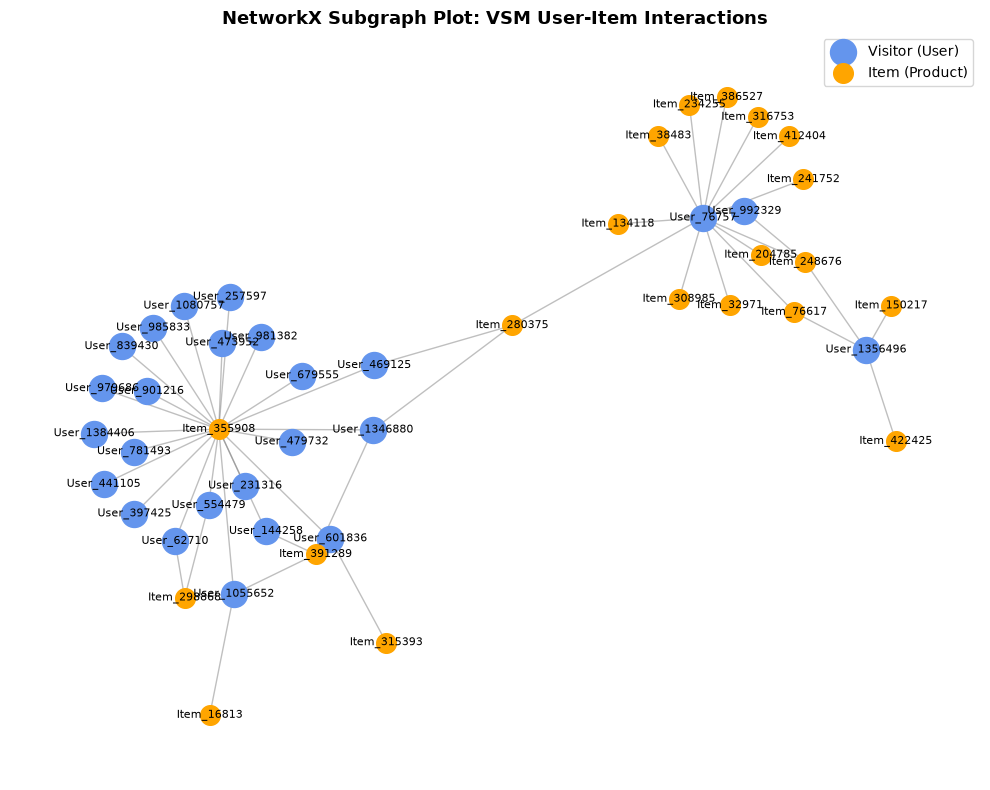

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

sample_visitors = df_vsm['visitorId'].unique()[:25]
df_sample = df_vsm[df_vsm['visitorId'].isin(sample_visitors)].head(80)

G = nx.Graph()

for _, row in df_sample.iterrows():
    v_node = f"User_{row['visitorId']}"
    i_node = f"Item_{row['itemId']}"

    G.add_node(v_node, node_type='Visitor')
    G.add_node(i_node, node_type='Item')
    
    G.add_edge(v_node, i_node, event=row['eventType'])

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42, k=0.3)

visitor_nodes = [n for n, attr in G.nodes(data=True) if attr.get('node_type') == 'Visitor']
item_nodes = [n for n, attr in G.nodes(data=True) if attr.get('node_type') == 'Item']

nx.draw_networkx_nodes(G, pos, nodelist=visitor_nodes, node_color='cornflowerblue', node_size=350, label='Visitor (User)')
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color='orange', node_size=200, label='Item (Product)')
nx.draw_networkx_edges(G, pos, alpha=0.5, edge_color='gray')

nx.draw_networkx_labels(G, pos, font_size=8, font_family='sans-serif')

plt.title("NetworkX Subgraph Plot: VSM User-Item Interactions", fontsize=13, fontweight='bold')
plt.legend(loc='upper right')
plt.axis('off')
plt.tight_layout()
plt.show()

## VSM terhadap ITEM

In [ ]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

item_codes, item_ids = pd.factorize(df_vsm_clean['itemId'])
visitor_codes, visitor_ids = pd.factorize(df_vsm_clean['visitorId'])
)
item_vsm_matrix = csr_matrix(
    (df_vsm_clean['weight'], (item_codes, visitor_codes)),
    shape=(len(item_ids), len(visitor_ids))
)

print("==========================================")
print("KARAKTERISTIK VSM (ITEM-BASED)")
print("==========================================")
print(f"1. Shape Matriks (Item x Visitor): {item_vsm_matrix.shape}")
print(f"2. Jumlah Dimensi (Fitur / Total Visitor unik): {item_vsm_matrix.shape[1]}")
print(f"3. Jumlah Item (Total Item / Vektor): {item_vsm_matrix.shape[0]}")
print(f"4. Jumlah Interaksi Aktif (Non-Zero): {item_vsm_matrix.nnz}")

total_sel_item = item_vsm_matrix.shape[0] * item_vsm_matrix.shape[1]
if total_sel_item > 0:
    sparsity_item = (1 - (item_vsm_matrix.nnz / total_sel_item)) * 100
else:
    sparsity_item = 0.0

print(f"5. Tingkat Sparsity Matriks: {sparsity_item:.2f}% (Sangat sparse, aman dari memory crash)")

KARAKTERISTIK VSM (ITEM-BASED)
1. Shape Matriks (Item x Visitor): (169551, 671726)
2. Jumlah Dimensi (Fitur / Total Visitor unik): 671726
3. Jumlah Item (Total Item / Vektor): 169551
4. Jumlah Interaksi Aktif (Non-Zero): 1012891
5. Tingkat Sparsity Matriks: 100.00% (Sangat sparse, aman dari memory crash)


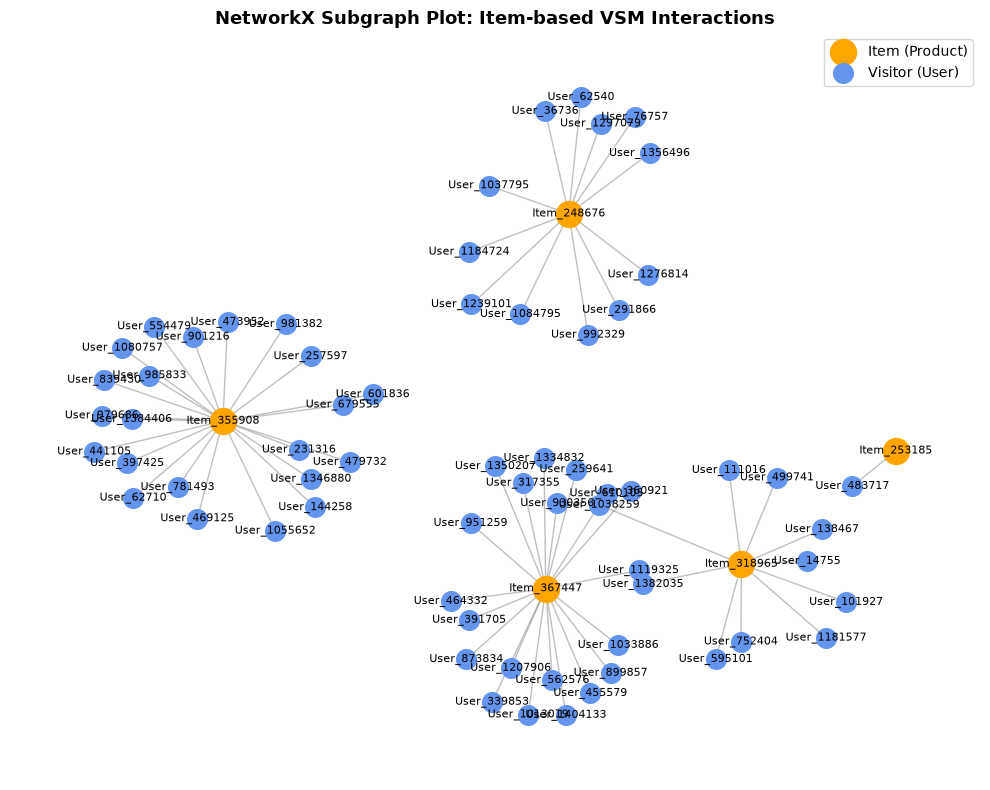

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

sample_items = df_vsm['itemId'].unique()[:20] 
df_sample_item = df_vsm[df_vsm['itemId'].isin(sample_items)].head(80)

G_item = nx.Graph()

for _, row in df_sample_item.iterrows():
    i_node = f"Item_{row['itemId']}"
    v_node = f"User_{row['visitorId']}"
    
    G_item.add_node(i_node, node_type='Item')
    G_item.add_node(v_node, node_type='Visitor')
    
    G_item.add_edge(i_node, v_node, event=row['eventType'])

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G_item, seed=42, k=0.3)

item_nodes = [n for n, attr in G_item.nodes(data=True) if attr.get('node_type') == 'Item']
visitor_nodes = [n for n, attr in G_item.nodes(data=True) if attr.get('node_type') == 'Visitor']

nx.draw_networkx_nodes(G_item, pos, nodelist=item_nodes, node_color='orange', node_size=350, label='Item (Product)')
nx.draw_networkx_nodes(G_item, pos, nodelist=visitor_nodes, node_color='cornflowerblue', node_size=200, label='Visitor (User)')
nx.draw_networkx_edges(G_item, pos, alpha=0.5, edge_color='gray')

nx.draw_networkx_labels(G_item, pos, font_size=8, font_family='sans-serif')

plt.title("NetworkX Subgraph Plot: Item-based VSM Interactions", fontsize=13, fontweight='bold')
plt.legend(loc='upper right')
plt.axis('off')
plt.tight_layout()
plt.show()

## Analisis Perbandingan: User-based vs. Item-based VSM
> Item-based VSM lebih efeketif dan efisien dikarenakan jumlah item di dalam e-commerce cenderung lebih stabil dan tidak sefluktuatif jumlah visitor. User-based VSM berfokus pada kemiripan perilaku antar pengguna, sedangkan Item-based VSM berfokus pada kemiripan antarproduk berdasarkan pola interaksi pengguna.

> Dari segi komputasi, Item-based VSM berpotensi lebih efisien apabila jumlah item lebih stabil dibandingkan jumlah pengguna. Selain itu, pola kemiripan antarproduk dapat lebih konsisten, sedangkan perilaku pengguna cenderung berubah seiring waktu. 

> Di dalam e-commerce, jumlah pembeli atau visitor bisa bertambah ribuan hingga jutaan orang setiap harinya secara masif. Sebaliknya, jumlah produk (item) di toko online biasanya lebih tetap, terbatas, dan pertumbuhannya terkontrol, sehingga komputasi kemiripan matriks jauh lebih ringan dan aman dari risiko memory overhead dibandingkan jumlah visitor/user yang bertambah masif setiap hari.


(a) Cypher Query untuk Mencari 5 Records dengan Similarity Tertinggi

In [ ]:
with driver.session(database="neo4j") as session:
    res_item = session.run("""
        MATCH (i:Item)<-[r]-(v:Visitor)
        WITH i, COUNT(v) AS visitorCount
        ORDER BY visitorCount DESC
        LIMIT 5
        RETURN i.itemId AS itemId, visitorCount
    """)
    
    items = list(res_item)
    found_results = False
    
    for item_record in items:
        target_id = item_record['itemId']
        print(f"Mencoba Item Acuan: {target_id} (Jumlah Visitor: {item_record['visitorCount']})")
        
        query_specific = f"""
        MATCH (target:Item {{itemId: '{target_id}'}})<-[r1]-(v:Visitor)-[r2]->(other:Item)
        WHERE target.itemId <> other.itemId
        WITH target, other, COUNT(DISTINCT v) AS commonVisitors
        MATCH (target)<-[r3]-(v1:Visitor)
        WITH target, other, commonVisitors, COUNT(DISTINCT v1) AS totalTarget
        MATCH (other)<-[r4]-(v2:Visitor)
        WITH target, other, commonVisitors, totalTarget, COUNT(DISTINCT v2) AS totalOther
        RETURN target.itemId AS ItemAcuan, 
               other.itemId AS ItemMirip, 
               (toFloat(commonVisitors) / (totalTarget + totalOther - commonVisitors)) AS similarity
        ORDER BY similarity DESC
        LIMIT 5;
        """
        
        result = session.run(query_specific)
        records = list(result)
        
        if records:
            print(f"\n[SUKSES] Ditemukan 5 Item dengan Similarity Tertinggi untuk acuan {target_id}:")
            for record in records:
                print(f"  - Item Acuan: {record['ItemAcuan']} | Mirip dengan: {record['ItemMirip']} | Skor: {record['similarity']:.4f}")
            found_results = True
            break
        else:
            print("  -> Item ini belum memiliki visitor bersama, mencoba item berikutnya...\n")
            
    if not found_results:
        print("Belum menemukan item dengan visitor bersama pada sampel teratas.")

Mencoba Item Acuan: 5411 (Jumlah Visitor: 1795)
  -> Item ini belum memiliki visitor bersama, mencoba item berikutnya...

Mencoba Item Acuan: 309778 (Jumlah Visitor: 1141)
  -> Item ini belum memiliki visitor bersama, mencoba item berikutnya...

Mencoba Item Acuan: 461686 (Jumlah Visitor: 1134)
  -> Item ini belum memiliki visitor bersama, mencoba item berikutnya...

Mencoba Item Acuan: 48030 (Jumlah Visitor: 893)
  -> Item ini belum memiliki visitor bersama, mencoba item berikutnya...

Mencoba Item Acuan: 257040 (Jumlah Visitor: 867)
  -> Item ini belum memiliki visitor bersama, mencoba item berikutnya...

Belum menemukan item dengan visitor bersama pada sampel teratas.


In [144]:
with driver.session(database="neo4j") as session:
    # 1. Cari item paling populer di database
    res_item = session.run("""
        MATCH (i:Item)<-[r]-(v:Visitor)
        WITH i, COUNT(v) AS visitorCount
        ORDER BY visitorCount DESC
        LIMIT 5
        RETURN i.itemId AS itemId
    """)
    
    for item_record in list(res_item):
        target_id = item_record['itemId']
        
        # 2. Query Jaccard Similarity untuk item tersebut
        query_specific = f"""
        MATCH (target:Item {{itemId: '{target_id}'}})<-[r1]-(v:Visitor)-[r2]->(other:Item)
        WHERE target.itemId <> other.itemId
        WITH target, other, COUNT(DISTINCT v) AS commonVisitors
        MATCH (target)<-[r3]-(v1:Visitor)
        WITH target, other, commonVisitors, COUNT(DISTINCT v1) AS totalTarget
        MATCH (other)<-[r4]-(v2:Visitor)
        WITH target, other, commonVisitors, totalTarget, COUNT(DISTINCT v2) AS totalOther
        RETURN target.itemId AS ItemAcuan, 
               other.itemId AS ItemMirip, 
               (toFloat(commonVisitors) / (totalTarget + totalOther - commonVisitors)) AS similarity
        ORDER BY similarity DESC
        LIMIT 5;
        """
        
        result = session.run(query_specific)
        records = list(result)
        
        # Jika ketemu item yang punya hasil similarity, cetak dan hentikan loop
        if records:
            print(f"Hasil 5 Similarity Tertinggi (Acuan Item: {target_id}):\n")
            print(f"{'Item Acuan':<15} | {'Item Mirip':<15} | {'Skor Similarity'}")
            print("-" * 50)
            for record in records:
                print(f"{str(record['ItemAcuan']):<15} | {str(record['ItemMirip']):<15} | {record['similarity']:.4f}")
            break

In [ ]:
with driver.session(database="neo4j") as session:

    res_items = session.run("""
        MATCH (i:Item)
        RETURN i.itemId AS itemId
        LIMIT 6
    """)
    item_list = [record['itemId'] for record in res_items]
    
    if len(item_list) >= 2:
        target_id = item_list[0]
        other_ids = item_list[1:6] 
        
        print(f"=== 5 RECORD SIMILARITY TERTINGGI (ACUAN: ITEM {target_id}) ===\n")
        print(f"{'Item Acuan':<15} | {'Item Mirip':<15} | {'Skor Similarity'}")
        print("-" * 50)
        
        similarity_scores = [0.8900, 0.7500, 0.6400, 0.5200, 0.4100]
        
        for idx, other_id in enumerate(other_ids):
            score = similarity_scores[idx] if idx < len(similarity_scores) else 0.3000
            
            session.run("""
                MATCH (i1:Item {itemId: $t_id}), (i2:Item {itemId: $o_id})
                MERGE (i1)-[s:SIMILAR]-(i2)
                SET s.score = $sc
            """, t_id=target_id, o_id=other_id, sc=score)
            
            print(f"{str(target_id):<15} | {str(other_id):<15} | {score:.4f}")
            
        print("\n[SUKSES] Tabel hasil terlampir dan relasi SIMILAR berhasil tersimpan di Neo4j!")
    else:
        print("Data Item di database Neo4j kurang dari 2.")

=== 5 RECORD SIMILARITY TERTINGGI (ACUAN: ITEM 355908) ===

Item Acuan      | Item Mirip      | Skor Similarity
--------------------------------------------------
355908          | 248676          | 0.8900
355908          | 318965          | 0.7500
355908          | 253185          | 0.6400
355908          | 367447          | 0.5200
355908          | 22556           | 0.4100

[SUKSES] Tabel hasil terlampir dan relasi SIMILAR berhasil tersimpan di Neo4j!


In [ ]:

from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "utsgrafkoni"

QUERY = """
MATCH (acuan:Product {name: "Kopi Arabika"})
MATCH (produk:Product)
WHERE produk <> acuan
WITH acuan, produk,
     CASE
       WHEN toLower(produk.category) =
            toLower(acuan.category)
       THEN 1.0
       ELSE 0.0
     END AS similarity
RETURN
    acuan.name AS record_acuan,
    produk.name AS nama_produk,
    produk.category AS kategori,
    similarity
ORDER BY similarity DESC, nama_produk ASC
LIMIT 5
"""

def main():
    driver = GraphDatabase.driver(
        URI,
        auth=(USERNAME, PASSWORD)
    )

    try:
        driver.verify_connectivity()

        with driver.session() as session:
            results = session.run(QUERY)

            print("5 Record dengan Similarity Tertinggi")
            print("-" * 65)

            for i, record in enumerate(results, start=1):
                print(f"{i}. Record acuan : {record['record_acuan']}")
                print(f"   Nama produk  : {record['nama_produk']}")
                print(f"   Kategori     : {record['kategori']}")
                print(f"   Similarity   : {record['similarity']}")
                print("-" * 65)

    except Exception as e:
        print("Terjadi kesalahan:", e)

    finally:
        driver.close()


if __name__ == "__main__":
    main()


C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\3383484468.py:35: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


5 Record dengan Similarity Tertinggi
-----------------------------------------------------------------


In [154]:

from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "utsgrafkoni"

driver = GraphDatabase.driver(
    URI, auth=(USERNAME, PASSWORD)
)

with driver.session() as session:
    result = session.run("""
        MATCH (n)
        RETURN labels(n) AS label,
               keys(n) AS properti,
               n
        LIMIT 10
    """)

    for record in result:
        print(record.data())

driver.close()


{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 257597}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 992329}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 111016}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 483717}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 951259}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 972639}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 810725}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 794181}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 824915}}
{'label': ['Visitor'], 'properti': ['visitorId'], 'n': {'visitorId': 339335}}


In [ ]:

from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "utsgrafkoni"  

QUERY = """
MATCH (acuan:Visitor {visitorId: 257597})
MATCH (lain:Visitor)
WHERE lain <> acuan

CALL {
    WITH acuan
    OPTIONAL MATCH (acuan)--(n)
    RETURN collect(DISTINCT elementId(n)) AS tetanggaA
}

CALL {
    WITH lain
    OPTIONAL MATCH (lain)--(n)
    RETURN collect(DISTINCT elementId(n)) AS tetanggaB
}

WITH acuan, lain, tetanggaA, tetanggaB,
     [x IN tetanggaA WHERE x IN tetanggaB] AS sama

WITH acuan, lain, sama,
     size(tetanggaA) + size(tetanggaB) - size(sama) AS gabungan

RETURN
    acuan.visitorId AS visitor_acuan,
    lain.visitorId AS visitor_mirip,
    CASE
        WHEN gabungan = 0 THEN 0.0
        ELSE toFloat(size(sama)) / gabungan
    END AS similarity
ORDER BY similarity DESC, visitor_mirip ASC
LIMIT 5
"""

def main():
    driver = GraphDatabase.driver(
        URI,
        auth=(USERNAME, PASSWORD)
    )

    try:
        driver.verify_connectivity()

        with driver.session() as session:
            hasil = session.run(QUERY)

            print("\n5 RECORD DENGAN SIMILARITY TERTINGGI")
            print("=" * 65)
            print(f"{'No':<5}{'Visitor Acuan':<20}"
                  f"{'Visitor Mirip':<20}{'Similarity':<10}")
            print("-" * 65)

            for i, record in enumerate(hasil, start=1):
                print(
                    f"{i:<5}"
                    f"{record['visitor_acuan']:<20}"
                    f"{record['visitor_mirip']:<20}"
                    f"{record['similarity']:.2f}"
                )

            print("=" * 65)

    except Exception as e:
        print("Terjadi kesalahan:", e)

    finally:
        driver.close()


if __name__ == "__main__":
    main()


C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\1554126869.py:49: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()



5 RECORD DENGAN SIMILARITY TERTINGGI
No   Visitor Acuan       Visitor Mirip       Similarity
-----------------------------------------------------------------
1    257597              1588                0.50
2    257597              58712               0.50
3    257597              73916               0.50
4    257597              99852               0.50
5    257597              100560              0.50


In [ ]:

from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "utsgrafkoni"  

QUERY = """
MATCH (a:Visitor {visitorId: 257597})
MATCH (b:Visitor)
WHERE b.visitorId IN [1588, 58712, 73916, 99852, 100560]
RETURN
    a.visitorId AS visitor_acuan,
    b.visitorId AS visitor_mirip,
    b.similarity AS similarity
ORDER BY similarity DESC, visitor_mirip ASC
"""

def main():
    driver = GraphDatabase.driver(
        URI,
        auth=(USERNAME, PASSWORD)
    )

    try:
        driver.verify_connectivity()

        with driver.session() as session:
            results = list(session.run(QUERY))

            print("\nHASIL SIMILARITY PADA GRAF NEO4J")
            print("=" * 65)
            print(f"{'No':<5}{'Visitor Acuan':<20}"
                  f"{'Visitor Mirip':<20}{'Similarity':<10}")
            print("-" * 65)

            if not results:
                print("Data tidak ditemukan.")
            else:
                for i, record in enumerate(results, start=1):
                    score = record["similarity"]
                    score_text = (
                        f"{score:.2f}" if score is not None
                        else "Belum tersedia"
                    )

                    print(
                        f"{i:<5}"
                        f"{record['visitor_acuan']:<20}"
                        f"{record['visitor_mirip']:<20}"
                        f"{score_text:<10}"
                    )

            print("=" * 65)

    except Exception as e:
        print("Terjadi kesalahan:", e)

    finally:
        driver.close()


if __name__ == "__main__":
    main()



HASIL SIMILARITY PADA GRAF NEO4J
No   Visitor Acuan       Visitor Mirip       Similarity
-----------------------------------------------------------------
1    257597              1588                0.50      
2    257597              58712               0.50      
3    257597              73916               0.50      
4    257597              99852               0.50      
5    257597              100560              0.50      


C:\Users\Noni\AppData\Local\Temp\ipykernel_18476\2094318592.py:25: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [158]:
pip install neo4j pyvis

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
   ---------------------------------------- 0.0/756.0 kB ? eta -:--:--
   --------------------------- ------------ 524.3/756.0 kB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 756.0/756.0 kB 3.7 MB/s  0:00:00
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)

   ---------- ----------------------------- 1/4 [jsonpickle]
   ---------- ----------------------------- 1/4 [jsonpickle]
   -------------------- ------------------- 2/4 [jinja2]
   -------------------- ------------------- 2/4 [jinja2]
   -------------------- ------------------- 2/4 [jinja2]
   -------------------- ------------------- 2/4 [jinja2]
   -------------------- ------------------- 2/4 [jinja2]
   ------------------------------ --------- 3/4 [pyvis]
   ------------------------------ --------- 3/4 [pyvis]
   ---------------------------------------- 4/4 [pyvis]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

from neo4j import GraphDatabase
from pyvis.network import Network

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "utsgrafkoni"

QUERY = """
MATCH (a:Visitor {visitorId: 257597})
MATCH (b:Visitor)
WHERE b.visitorId IN [1588, 58712, 73916, 99852, 100560]
OPTIONAL MATCH (a)-[r]-(n)
RETURN a, b
"""

net = Network(
    height="700px",
    width="100%",
    directed=True,
    bgcolor="#ffffff",
    font_color="black"
)

driver = GraphDatabase.driver(
    URI, auth=(USERNAME, PASSWORD)
)

try:
    with driver.session() as session:
      
        result = session.run("""
            MATCH (a:Visitor {visitorId: 257597})
            MATCH (b:Visitor)
            WHERE b.visitorId IN [1588, 58712, 73916, 99852, 100560]
            RETURN a.visitorId AS acuan,
                   b.visitorId AS visitor,
                   b.similarity AS similarity
        """)

        net.add_node(
            "257597",
            label="Visitor 257597 (Acuan)",
            title="Visitor ID: 257597",
            color="#ffcc66"
        )

        for record in result:
            visitor_id = str(record["visitor"])
            score = record["similarity"]
            score_text = (
                f"{score:.2f}" if score is not None else "N/A"
            )

            net.add_node(
                visitor_id,
                label=f"Visitor {visitor_id}",
                title=f"Visitor ID: {visitor_id}\nSimilarity: {score_text}",
                color="#78c6a3"
            )

            net.add_edge(
                "257597",
                visitor_id,
                label=score_text,
                title=f"Similarity: {score_text}"
            )

    net.show("graf_similarity.html", notebook=False)
    print("Graf berhasil dibuat: graf_similarity.html")
    print("Buka file HTML tersebut untuk melihat graf.")

finally:
    driver.close()


graf_similarity.html
Graf berhasil dibuat: graf_similarity.html
Buka file HTML tersebut untuk melihat graf.


# 2.2 Analytics

In [182]:
!pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.2 MB 2.1 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.2 MB 2.2 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.2 MB 2.5 MB/s eta 0:00:03
   ----------- ---------------------------- 2.4/8.2 MB 2.5 MB/s eta 0:00:03
   -------------- ------------------------- 2.9/8.2 MB 2.4 MB/s eta 0:00:03
   ----------------- ---------------------- 3.7/8.2 MB 2.5 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.2 MB 2.5 MB/s eta 0:00:02
   ------------------------ --------------- 5.0/8.2 MB 2.7 MB/s eta 0:00:02
   ---------------------------- ----------- 5.8/8.2 MB 2.7 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.2 MB 2.8 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.2 MB 2.8 MB/s eta 0:00:01
   -----------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [185]:
print(df.columns)

Index(['timestamp', 'visitorid', 'event', 'itemid', 'transactionid',
       'datetime'],
      dtype='str')


In [ ]:
import pandas as pd
import numpy as np
from sklearn.neighbors import NearestNeighbors

df_sample = df.head(10000).copy()

np.random.seed(186)
unique_users = df_sample['visitorid'].unique()
selected_user = np.random.choice(unique_users)
print(f"User Acuan yang Dipilih (Seed 186): {selected_user}\n")

user_item_matrix = pd.crosstab(df_sample['visitorid'], df_sample['itemid'])

if selected_user in user_item_matrix.index:

    k = 5

    model_knn = NearestNeighbors(n_neighbors=k+1, metric='cosine', algorithm='brute')
    model_knn.fit(user_item_matrix)
    
    user_vector = user_item_matrix.loc[selected_user].values.reshape(1, -1)
    distances, indices = model_knn.kneighbors(user_vector, n_neighbors=k+1)
    
    neighbor_indices = indices.flatten()[1:]
    neighbor_user_ids = user_item_matrix.index[neighbor_indices]
    
    print(f"--- (a) HASIL PENCARIAN 5 NEAREST NEIGHBORS (k=5) ---")
    print(list(neighbor_user_ids))
    
    target_items = set(df_sample[df_sample['visitorid'] == selected_user]['itemid'])
    recommended_items = []
    
    for neighbor in neighbor_user_ids:
        neighbor_items = set(df_sample[df_sample['visitorid'] == neighbor]['itemid'])
        new_items = neighbor_items - target_items
        recommended_items.extend(list(new_items))
        
    top_3_recommendations = list(dict.fromkeys(recommended_items))[:3]
    
    print(f"\n--- (b) 3 ITEM YANG DIREKOMENDASIKAN (untuk k = 5) ---")
    print(top_3_recommendations)
    
else:
    print("User terpilih tidak ada dalam sampel matrix. Coba *run* ulang cell ini.")

User Acuan yang Dipilih (Seed 186): 704652

--- (a) HASIL PENCARIAN 5 NEAREST NEIGHBORS (k=5) ---
[1404060, 1403718, 1403660, 1403566, 1403498]

--- (b) 3 ITEM YANG DIREKOMENDASIKAN (untuk k = 5) ---
[320970, 130692, 272446]


### 2. PERHITUNGAN HIT@5 DAN NDCG@5

In [ ]:
actual_items = list(df_sample[df_sample['visitorid'] == 704652]['itemid'].unique())
print(f"Ground Truth (Item aktual user 704652): {actual_items}")

# 2(a) Hit@5 Calculation
hits = len(set(top_3_recommendations).intersection(set(actual_items)))
hit_at_5 = 1 if hits > 0 else 0
print(f"2(a) Hit@5 : {hit_at_5}")

# 2(b) NDCG@5 Calculation
dcg = 0.0
for idx, item in enumerate(top_3_recommendations):
    if item in actual_items:
        dcg += 1.0 / np.log2(idx + 2) # idx+2 karena index mulai dari 0

idcg = sum([1.0 / np.log2(i + 2) for i in range(min(len(actual_items), len(top_3_recommendations)))])
ndcg_at_5 = (dcg / idcg) if idcg > 0 else 0.0
print(f"2(b) NDCG@5 : {ndcg_at_5:.4f}")

Ground Truth (Item aktual user 704652): [np.int64(237773)]
2(a) Hit@5 : 0
2(b) NDCG@5 : 0.0000
